# Age-structured SEIR with a POLYMOD-type contact matrix

Homogeneous-mixing models are a poor description of directly transmitted childhood
infections. The force of infection depends strongly on age: children make more
contacts than adults and they mix assortatively. For measles — the textbook case,
with $R_0$ usually quoted between 12 and 18 — that structure is not a refinement,
it is the whole story: the herd-immunity threshold $1 - 1/R_0$ sits between 92%
and 95%, so a few points of coverage decide between extinction and a nationwide
epidemic.

`AgeStructuredSEIR` implements the age-structured MSEIR model with

* $A$ age groups $\times$ 5 compartments (maternally immune, susceptible,
  exposed, infectious, removed) — $5A$ state variables;
* an explicit ageing chain, optional births and mortality;
* an optional routine vaccination programme in one chosen age group;
* a contact matrix that satisfies detailed balance exactly.

This notebook walks through the model, its contact matrix, the calibration of
$R_0$, and what happens to a vaccinated population when the programme is
interrupted.

> **Requires** `epimodels` with the age-structured model (`epimodels.continuous.age_structured`).

## 0. Setup

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from epimodels.continuous.age_structured import AgeStructuredSEIR
from epimodels.tools.contact_matrix import (
    DEFAULT_AGE_BOUNDS,
    age_group_labels,
    check_reciprocity,
    polymod_like_contact_matrix,
)
from epimodels.interventions import Intervention, Scenario

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.labelsize": 10})

## 1. The contact matrix

`polymod_like_contact_matrix` builds a matrix with the *qualitative* shape of the
empirical POLYMOD matrices (Mossong et al., 2008): 9-10 contacts/day in infants, a
peak near 18 in 10-15 year-olds, and 7-8 in the elderly.

It is constructed in two steps. A symmetric affinity

$$A_{ij} = u_i\,u_j\,e^{-|a_i-a_j|/\tau}$$

combines an age-specific activity profile $u$ with an age-assortative kernel, and
the per-capita rates follow as

$$C_{ij} = \frac{A_{ij}\,N_j}{\sum_k N_k}.$$

Because $N_i C_{ij} = u_i u_j e^{-|a_i-a_j|/\tau} N_i N_j / \sum_k N_k$ is manifestly
symmetric, the result satisfies detailed balance **by construction**, for any
activity vector and any population. The activity vector itself is obtained by a
damped fixed point so that group $i$ makes contacts in proportion to the requested
profile.

Let us use the age structure of Brazil (2022 census) on the default 21-group grid,
which resolves infancy in one-year bands.

In [ ]:
# Resident population by age group, Brazil 2022 census (millions of people),
# in the order of DEFAULT_AGE_BOUNDS: 0-1, 1-2, 2-3, 3-4, 4-5, 5-10, ..., 80+.
POPULATION = np.array(
    [2.60, 2.60, 2.65, 2.70, 2.75,
     14.0, 14.5, 15.0, 16.5, 17.0, 17.0, 16.0, 14.5, 13.0, 11.5, 9.5, 7.5, 5.5,
     4.0, 2.5, 3.0]
) * 1e6

TOTAL = float(POPULATION.sum())
YEAR = 365.25                 # model time is one day
BIRTHS = 2.54e6 / YEAR        # ~2.54 million live births per year
MU = BIRTHS / TOTAL           # mortality that keeps the population stationary

LABELS = age_group_labels(DEFAULT_AGE_BOUNDS)
CONTACT = polymod_like_contact_matrix(DEFAULT_AGE_BOUNDS, population=POPULATION)

print(f"age groups          : {CONTACT.shape[0]}")
print(f"total population    : {TOTAL/1e6:.1f} million")
print(f"detailed balance    : {check_reciprocity(CONTACT, POPULATION)}")
print("\ncontacts per day, by age group")
for i in (0, 5, 6, 7, 12, 20):
    print(f"  {LABELS[i]:>6} : {CONTACT[i].sum():5.1f}")

age groups          : 21
total population    : 194.3 million
detailed balance    : True

contacts per day, by age group
     0-1 :   9.7
    5-10 :  17.0
   10-15 :  18.0
   15-20 :  17.8
   40-45 :  14.2
     80+ :   7.9


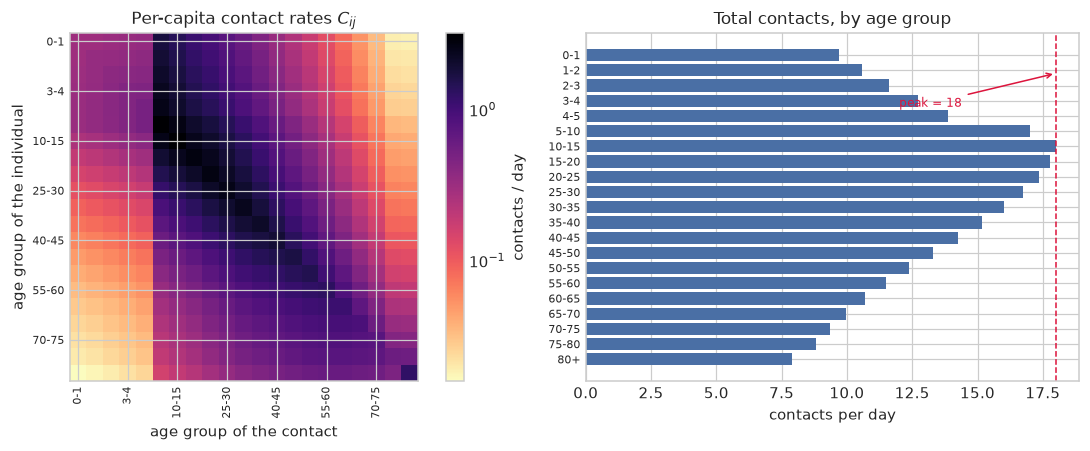

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.15, 1]})

im = axes[0].imshow(CONTACT, cmap="magma_r", norm=plt.matplotlib.colors.LogNorm())
axes[0].set_title("Per-capita contact rates $C_{ij}$")
axes[0].set_xlabel("age group of the contact")
axes[0].set_ylabel("age group of the individual")
ticks = list(range(0, 21, 3))
axes[0].set_xticks(ticks); axes[0].set_yticks(ticks)
axes[0].set_xticklabels([LABELS[i] for i in ticks], rotation=90, fontsize=7)
axes[0].set_yticklabels([LABELS[i] for i in ticks], fontsize=7)
fig.colorbar(im, ax=axes[0], fraction=0.046, label="contacts / day")

axes[1].barh(range(21), CONTACT.sum(axis=1), color="#4a6fa5")
axes[1].set_yticks(range(21)); axes[1].set_yticklabels(LABELS, fontsize=7)
axes[1].invert_yaxis()
axes[1].set_xlabel("contacts per day")
axes[1].set_title("Total contacts, by age group")
axes[1].axvline(18.0, ls="--", lw=1, color="crimson")
axes[1].annotate("peak = 18", xy=(18.0, 1.2), xytext=(12.0, 3.4),
                 color="crimson", fontsize=8,
                 arrowprops=dict(arrowstyle="->", color="crimson", lw=1))
plt.tight_layout()

## 2. Detailed balance is not a cosmetic detail

The next-generation matrix of this model is

$$K_{ij} = \frac{\beta}{\gamma+\mu}\,\frac{N_i}{N_j}\,C_{ij}, \qquad R_0 = \rho(K).$$

$K$ is **not symmetric** — the factors $N_i/N_j$ break symmetry. It is only *similar* to
a symmetric matrix. With $D = \operatorname{diag}(\sqrt{N})$,

$$\left(D^{-1} K D\right)_{ij} = \frac{\beta}{\gamma+\mu}\sqrt{\frac{N_i}{N_j}}\,C_{ij},$$

whose $(i,j)$ and $(j,i)$ entries coincide exactly when $N_iC_{ij} = N_jC_{ji}$ — that is,
when the contact matrix satisfies detailed balance.

`numpy.linalg.eigvalsh` assumes a symmetric argument and silently reads **one triangle**.
So there are two independent ways to get a wrong $R_0$ with no warning: hand it $K$
directly (it is never symmetric), or hand it $D^{-1}KD$ when detailed balance does not
hold. The cell below shows both, next to the one route that always works.

In [ ]:
def next_generation_operator(matrix, population, beta, gamma, mu=0.0):
    return beta / (gamma + mu) * (population[:, None] / population[None, :]) * matrix

def symmetrise(K, population):
    '''Similarity transform D^-1 K D, with D = diag(sqrt(N)).'''
    d = np.sqrt(population)
    return K / d[:, None] * d[None, :]

beta_demo, gamma_demo = 0.1, 1 / 8


def report(name, matrix):
    K = next_generation_operator(matrix, POPULATION, beta_demo, gamma_demo)
    S = symmetrise(K, POPULATION)
    print(f"\n{name}")
    print(f"  detailed balance             : {check_reciprocity(matrix, POPULATION)}")
    print(f"  K symmetric                  : {np.allclose(K, K.T)}")
    print(f"  D^-1 K D symmetric           : {np.allclose(S, S.T)}")
    print(f"  eigvals(K)   -- always valid : {np.max(np.abs(np.linalg.eigvals(K))):.4f}")
    print(f"  eigvalsh(D^-1 K D)           : {np.max(np.abs(np.linalg.eigvalsh(S))):.4f}")
    print(f"  eigvalsh(K)  -- on K as-is   : {np.max(np.abs(np.linalg.eigvalsh(K))):.4f}")


report("Parametric matrix (reciprocal by construction)", CONTACT)

# Break reciprocity: make infants four times as mobile as balance allows.
broken = CONTACT.copy()
broken[0, :] *= 4.0
report("Same matrix with row 0 quadrupled (reciprocity broken)", broken)

print("\nWith a reciprocal matrix the transformed operator is genuinely symmetric and")
print("eigvalsh(D^-1 K D) agrees with eigvals(K). Break reciprocity and the transform no")
print("longer symmetrises anything: eigvalsh reads a triangle and understates R0.")


Parametric matrix (reciprocal by construction)
  detailed balance             : True
  K symmetric                  : False
  D^-1 K D symmetric           : True
  eigvals(K)   -- always valid : 12.3596
  eigvalsh(D^-1 K D)           : 12.3596
  eigvalsh(K)  -- on K as-is   : 14.4313

Same matrix with row 0 quadrupled (reciprocity broken)
  detailed balance             : False
  K symmetric                  : False
  D^-1 K D symmetric           : False
  eigvals(K)   -- always valid : 12.6049
  eigvalsh(D^-1 K D)           : 12.3645
  eigvalsh(K)  -- on K as-is   : 14.4501

With a reciprocal matrix the transformed operator is genuinely symmetric and
eigvalsh(D^-1 K D) agrees with eigvals(K). Break reciprocity and the transform no
longer symmetrises anything: eigvalsh reads a triangle and understates R0.


## 3. Building the model

The constructor reconciles the contact matrix with the reference population and turns
the age-group widths into ageing rates ($a_i = 1/\text{width}$, zero for the
open-ended last group, so that the ageing terms telescope).

In [ ]:
model = AgeStructuredSEIR(population=POPULATION)

print(f"age groups        : {model.n_ages}")
print(f"state variables   : {model.dimension}  (5 compartments x {model.n_ages} groups)")
print(f"time unit         : {model.time_per_year} steps per year (days)")
print(f"vaccination group : index {model.vaccination_age_index}"
      f" -> {model.age_labels[model.vaccination_age_index]} years")
print(f"parameters        : {list(model.parameters)}")
print(f"\nageing rate, first group: {model.ageing_rates[0]:.6f} per day"
      f"   last group: {model.ageing_rates[-1]:.6f}")
print("state variable order (first 10):", list(model.state_variables)[:10])

age groups        : 21
state variables   : 105  (5 compartments x 21 groups)
time unit         : 365.25 steps per year (days)
vaccination group : index 1 -> 1-2 years
parameters        : ['beta', 'epsilon', 'gamma', 'omega', 'births', 'mu', 'vaccination']

ageing rate, first group: 0.002738 per day   last group: 0.000000
state variable order (first 10): ['M_0', 'M_1', 'M_2', 'M_3', 'M_4', 'M_5', 'M_6', 'M_7', 'M_8', 'M_9']


The optional parameters (`omega`, `births`, `mu`, `vaccination`) have defaults and are
filled in automatically — only `beta`, `epsilon` and `gamma` are mandatory.

### Calibrating $R_0$

`scale_beta_for_r0` inverts the spectral-radius relation, so we can work with an
epidemiological quantity instead of a transmission rate. Note the `mu` argument: $R_0$
is defined with the demographic turnover in the denominator of $K$, so a transmission
rate calibrated ignoring mortality will land slightly below target once mortality is
switched on.

`vaccination_rate_for_coverage` converts a coverage target into a rate. An individual
stays in the targeted group for a time $1/a_i$ and is vaccinated at rate $v$, so the
fraction vaccinated before ageing out is $v/(v+a_i)$, and reaching coverage $p$
requires $v = a_i\,p/(1-p)$.

In [ ]:
GAMMA = 1 / 8            # 8-day infectious period
EPSILON = 1 / 8          # 8-day latent period
R0_TARGET = 12.0         # measles: 12-18 in the literature

# Fraction of each cohort effectively immunised by the routine programme:
# 95% coverage x (93% / 97%) two-dose vaccine effectiveness.
PROTECTION = 0.943

BETA = model.scale_beta_for_r0(R0_TARGET, gamma=GAMMA, mu=MU, population=POPULATION)
V_RATE = model.vaccination_rate_for_coverage(PROTECTION)

print(f"beta for R0 = {R0_TARGET}   : {BETA:.6f} per day")
print(f"vaccination rate     : {V_RATE:.6f} per day ({V_RATE*YEAR:.2f} per year)")
print(f"  -> cohort coverage : {V_RATE/(V_RATE + model.ageing_rates[model.vaccination_age_index]):.3f}")
print(f"critical coverage    : {100 * (1 - 1 / R0_TARGET):.2f}%")

# A population that has eliminated measles keeps roughly 1/R0 of its members susceptible.
inits = model.initial_conditions(
    POPULATION, infectious=[10.0] + [0.0] * 20, immune_fraction=PROTECTION
)
print(f"\nsum(inits) == total population : {np.isclose(sum(inits), TOTAL)}")
print(f"susceptible share at t = 0     : {100 * sum(inits[21:42]) / TOTAL:.2f}%")

beta for R0 = 12.0   : 0.097118 per day
vaccination rate     : 0.045295 per day (16.54 per year)
  -> cohort coverage : 0.943
critical coverage    : 91.67%

sum(inits) == total population : True
susceptible share at t = 0     : 5.70%


In [ ]:
def params_for(protection):
    '''Parameter set for a given level of routine protection.'''
    return {
        "beta": BETA,
        "epsilon": EPSILON,
        "gamma": GAMMA,
        "births": BIRTHS,
        "mu": MU,
        "vaccination": model.vaccination_rate_for_coverage(protection),
    }


# A one-day run is enough to populate the parameter values and expose R0.
model(inits, [0, 1.0], TOTAL, params_for(PROTECTION))

print(f"R0 recovered by the model : {model.R0:.6f}")
print(f"herd-immunity threshold   : {100 * (1 - 1 / model.R0):.2f}%")
print(f"effective protection      : {100 * PROTECTION:.1f}%")
print(f"R_eff at t = 0            : {model.R0 * (1 - PROTECTION):.3f}"
      f"   (susceptible pool: {100*(1-PROTECTION):.1f}%)")

R0 recovered by the model : 12.000000
herd-immunity threshold   : 91.67%
effective protection      : 94.3%
R_eff at t = 0            : 0.684   (susceptible pool: 5.7%)


## 4. Holding the line

We now run the model for 25 years with the routine programme in place. Births feed the
maternally-immune compartment, maternal antibodies wane at rate $\omega$, and the 1-2
year cohort is vaccinated as it ages through the target group.

The model exposes the age-aggregated compartments under their plain names
(`traces["I"]`, `traces["S"]`, ...) alongside the per-group variables (`I_0`, `I_1`,
...), so utilities written for single-group models keep working.

In [ ]:
def run(protection=PROTECTION, stop_after_years=None, years=25):
    '''Simulate the programme, optionally withdrawing vaccination at a given time.'''
    m = AgeStructuredSEIR(population=POPULATION)
    params = params_for(protection)
    ics = m.initial_conditions(
        POPULATION, [10.0] + [0.0] * 20, immune_fraction=protection
    )
    trange = [0.0, YEAR * years]
    t_eval = np.arange(0.0, trange[1] + 1e-9, 1.0)   # daily output, for the quadrature below

    if stop_after_years is None:
        m(ics, trange, TOTAL, params, t_eval=t_eval)
        traces = m.traces
    else:
        scenario = Scenario(
            "interrupted", m, params=params, initial_conditions=ics,
            trange=trange, totpop=TOTAL,
            interventions=[Intervention("vaccination",
                                        start=YEAR * stop_after_years,
                                        new_value=0.0)],
        )
        scenario.run(t_eval=t_eval)
        traces = scenario.traces
        # Scenario simulates a deep copy, so `m` itself was never run and its `R0`
        # is still None. One short step populates the parameter values.
        m(ics, [0.0, 1.0], TOTAL, params)
    return m, traces


model_kept, traces_kept = run()

print(f"R0                 : {model_kept.R0:.2f}")
print(f"peak infectious    : {model_kept.summary()['peak_I']:,.0f}"
      f"   (the 10 cases we seeded)")
print(f"final susceptibles : {100 * traces_kept['S'][-1] / TOTAL:.2f}% of the population")
print(f"threshold 1/R0     : {100 / model_kept.R0:.2f}%")

R0                 : 12.00
peak infectious    : 10   (the 10 cases we seeded)
final susceptibles : 6.42% of the population
threshold 1/R0     : 8.33%


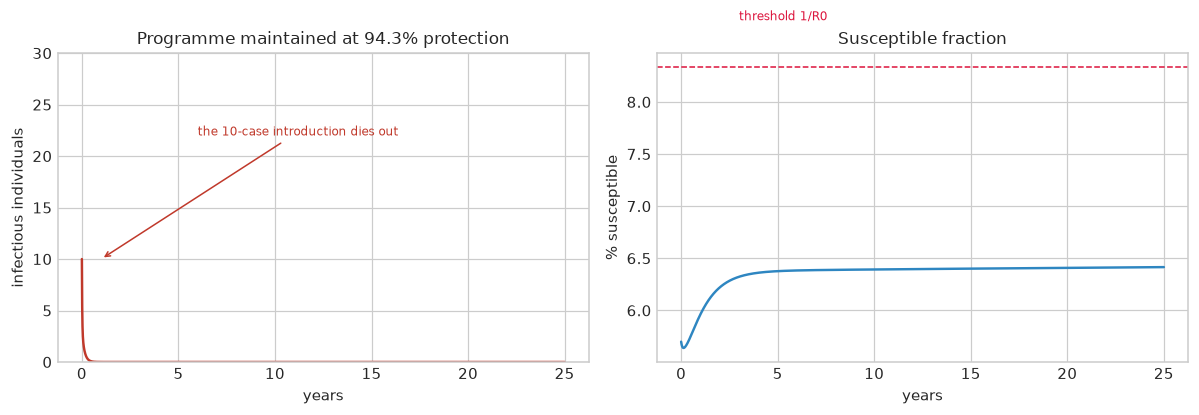

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))

t = np.asarray(traces_kept["time"]) / YEAR
axes[0].plot(t, traces_kept["I"], color="#c0392b", lw=1.6)
axes[0].set_title("Programme maintained at 94.3% protection")
axes[0].set_xlabel("years"); axes[0].set_ylabel("infectious individuals")
axes[0].set_ylim(0, 30)
axes[0].annotate("the 10-case introduction dies out", xy=(1.0, 10), xytext=(6, 22),
                 fontsize=8, color="#c0392b",
                 arrowprops=dict(arrowstyle="->", color="#c0392b", lw=1))

axes[1].plot(t, 100 * traces_kept["S"] / TOTAL, color="#2e86c1", lw=1.6)
axes[1].axhline(100 / model_kept.R0, ls="--", lw=1, color="crimson")
axes[1].annotate("threshold 1/R0", xy=(14, 100 / model_kept.R0),
                 xytext=(3.0, 100 / model_kept.R0 + 0.45),
                 fontsize=8, color="crimson")
axes[1].set_title("Susceptible fraction")
axes[1].set_xlabel("years"); axes[1].set_ylabel("% susceptible")
plt.tight_layout()

## 5. Withdrawing the programme

`Intervention` modifies a parameter over a time window, and `Scenario` bundles a model
with its parameters and interventions. Here routine vaccination is switched off after
two years.

The susceptible pool then refills from births at a rate set by $1/R_0$, and the epidemic
takes off years later — long after the decision that caused it.

In [ ]:
model_stop, traces_stop = run(stop_after_years=2.0)
t_stop = np.asarray(traces_stop["time"]) / YEAR
I_stop = np.asarray(traces_stop["I"])

peak = I_stop.max()
peak_year = t_stop[I_stop.argmax()]
print(f"peak infectious : {peak:,.0f}  ({100 * peak / TOTAL:.1f}% of the population)")
print(f"peak year       : {peak_year:.1f}  (vaccination stopped at year 2)")
print(f"R0              : {model_stop.R0:.2f}")

peak infectious : 1,585,727  (0.8% of the population)
peak year       : 7.9  (vaccination stopped at year 2)
R0              : 12.00


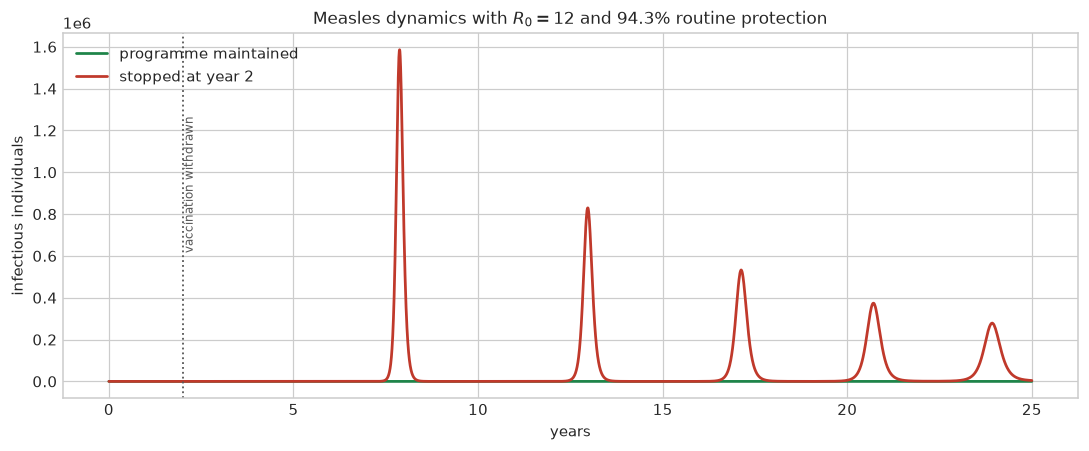

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(t, traces_kept["I"], color="#1e8449", lw=1.8, label="programme maintained")
ax.plot(t_stop, I_stop, color="#c0392b", lw=1.8, label="stopped at year 2")
ax.axvline(2.0, ls=":", lw=1.2, color="0.35")
ax.annotate("vaccination withdrawn", xy=(2.0, 0.80 * peak), fontsize=8,
            color="0.35", rotation=90, va="top")
ax.set_xlabel("years"); ax.set_ylabel("infectious individuals")
ax.set_title(f"Measles dynamics with $R_0 = {model_stop.R0:.0f}$ and 94.3% routine protection")
ax.legend(loc="upper left")
plt.tight_layout()

## 6. Who pays

The traces give $I_i(t)$ and $S_i(t)$ per group, so cumulative infections in group $i$
are the integral of the force of infection times the susceptible pool:

$$Z_i = \int_0^T \beta S_i(t) \sum_j C_{ij} \frac{I_j(t)}{N_j}\, dt .$$

Integrating this over the daily output grid reproduces the susceptible balance to about
$10^{-6}$ relative error. Because individuals age *into* groups, incidence has to be
expressed per person-year of exposure rather than per initial head count — otherwise
infants come out above 100% incidence.

In [ ]:
def cumulative_incidence(traces, beta):
    '''Cumulative infections per age group, by quadrature of the force of infection.'''
    t = np.asarray(traces["time"])
    I = np.array([traces[f"I_{i}"] for i in range(len(POPULATION))])
    S = np.array([traces[f"S_{i}"] for i in range(len(POPULATION))])
    force = beta * (CONTACT @ (I / POPULATION[:, None]))
    return np.trapezoid(force * S, x=t, axis=1)


def person_years(traces):
    '''Exposure time accumulated by each age group.'''
    t = np.asarray(traces["time"])
    N = np.array([
        sum(traces[f"{c}_{i}"] for c in "MSEIR") for i in range(len(POPULATION))
    ])
    return np.trapezoid(N, x=t, axis=1) / YEAR


incidence = cumulative_incidence(traces_stop, BETA)
exposure = person_years(traces_stop)
rate = 1e5 * incidence / exposure

print(f"cumulative infections : {incidence.sum()/1e6:.2f} million")
print(f"share below 20 years  : {100 * incidence[:8].sum() / incidence.sum():.0f}%"
      f"   (that band is {100 * POPULATION[:8].sum() / TOTAL:.0f}% of the population)")
print("\nage group   incidence / 100k person-years   share of infections")
for i in (0, 1, 2, 5, 6, 7, 8, 12, 16, 20):
    print(f"  {LABELS[i]:>6}    {rate[i]:12,.0f}                     {100*incidence[i]/incidence.sum():5.1f}%")

cumulative infections : 55.21 million
share below 20 years  : 88%   (that band is 29% of the population)

age group   incidence / 100k person-years   share of infections
     0-1           8,346                       9.5%
     1-2          10,871                      12.2%
     2-3          11,311                      12.6%
    5-10           3,973                      21.4%
   10-15           1,400                       7.5%
   15-20             569                       3.1%
   20-25             319                       1.8%
   40-45             176                       1.1%
   60-65             133                       0.6%
     80+             109                       0.6%


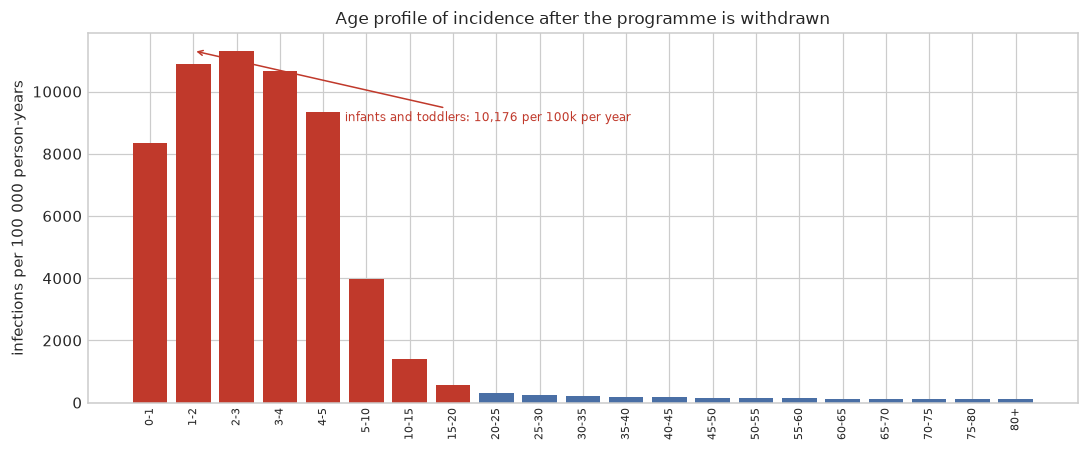

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.2))
colours = ["#c0392b" if i < 8 else "#4a6fa5" for i in range(len(POPULATION))]
ax.bar(range(len(POPULATION)), rate, color=colours)
ax.set_xticks(range(len(POPULATION)))
ax.set_xticklabels(LABELS, rotation=90, fontsize=7)
ax.set_ylabel("infections per 100 000 person-years")
ax.set_title("Age profile of incidence after the programme is withdrawn")
ax.annotate(f"infants and toddlers: {rate[:3].mean():,.0f} per 100k per year",
            xy=(1.0, rate[:3].max()), xytext=(4.5, 0.80 * rate.max()),
            fontsize=8, color="#c0392b",
            arrowprops=dict(arrowstyle="->", color="#c0392b", lw=1))
plt.tight_layout()

## 7. Sensitivity to $R_0$

The published range for measles is wide, and the conclusions are sensitive to it. Under
homogeneous mixing the effective reproduction number at protection level $p$ is
$R_\mathrm{eff} = R_0(1-p)$, so the coverage needed grows with $R_0$:

| $R_0$ | herd-immunity threshold $1-1/R_0$ | $R_\mathrm{eff}$ at 94.3% protection |
|------:|----------------------------------:|-------------------------------------:|
| 12 | 91.7% | 0.68 |
| 15 | 93.3% | 0.86 |
| 18 | 94.4% | 1.03 |

At the top of the range the programme is already below the threshold. The
age-structured model can shift these numbers, because susceptibles are not distributed
like the population — which is precisely why the matrix matters.

   R0  beta (per day)   threshold   R_eff at 94.3%
   12        0.097118       91.7%            0.684
   15        0.121398       93.3%            0.855
   18        0.145677       94.4%            1.026


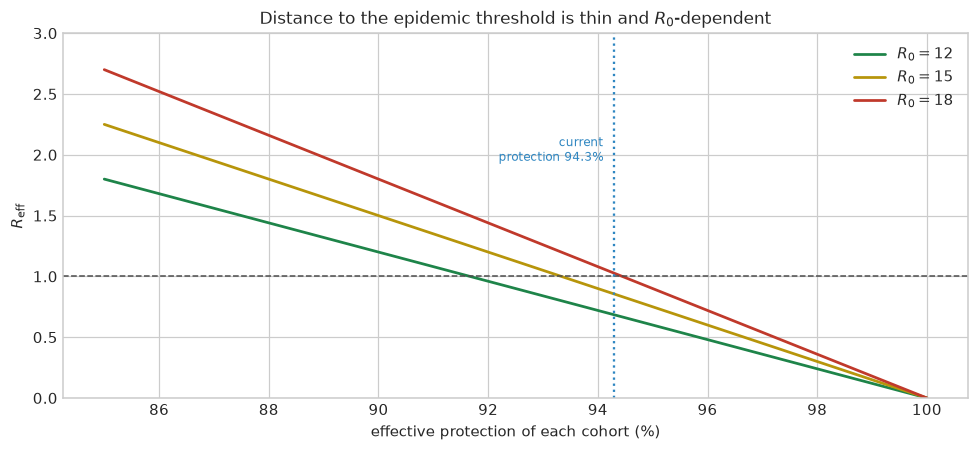

In [ ]:
r0_grid = np.array([12.0, 15.0, 18.0])
protection_grid = np.linspace(0.85, 1.0, 151)

print(f"{'R0':>5} {'beta (per day)':>15} {'threshold':>11} {'R_eff at 94.3%':>16}")
for r0 in r0_grid:
    b = model.scale_beta_for_r0(r0, gamma=GAMMA, mu=MU, population=POPULATION)
    print(f"{r0:5.0f} {b:15.6f} {100*(1-1/r0):10.1f}% {r0*(1-PROTECTION):16.3f}")

fig, ax = plt.subplots(figsize=(9, 4.2))
for r0, colour in zip(r0_grid, ["#1e8449", "#b7950b", "#c0392b"]):
    ax.plot(100 * protection_grid, r0 * (1 - protection_grid), color=colour,
            lw=1.8, label=f"$R_0 = {r0:.0f}$")
ax.axhline(1.0, color="0.3", ls="--", lw=1)
ax.axvline(100 * PROTECTION, color="#2e86c1", ls=":", lw=1.5)
ax.annotate("current\nprotection 94.3%", xy=(100 * PROTECTION - 0.2, 1.95),
            fontsize=8, color="#2e86c1", ha="right")
ax.set_xlabel("effective protection of each cohort (%)")
ax.set_ylabel("$R_\\mathrm{eff}$")
ax.set_title("Distance to the epidemic threshold is thin and $R_0$-dependent")
ax.set_ylim(0, 3)
ax.legend()
plt.tight_layout()

## 8. Caveats worth knowing before trusting the numbers

A few properties of this model are easy to get wrong, and they surface in results:

1. **`summary()["attack_rate"]` is not usable with demography.** It is defined as
   $(S_0 - S_T)/S_0$, and births keep refilling the susceptible pool, so it can come out
   *negative* over long horizons. Use the quadrature of section 6 instead.

2. **Quadrature needs a fine output grid.** The default solver returns ~160 points for an
   8-year run, which gives up to 14% error per age group. Pass
   `t_eval=np.arange(0, tf, 1.0)`.

3. **The force of infection uses the reference population**, not the running $N_i(t)$ —
   that is what makes the ageing terms telescope and keeps the total exactly conserved.
   Consistency between the model and any post-hoc incidence calculation requires using
   the same reference.

4. **`Scenario` runs a deep copy of the model**, so a `Scenario`-based run leaves the
   original object un-simulated (its `R0` is `None`).

5. **`polymod_like_contact_matrix` is not a fit to POLYMOD.** It reproduces the shape;
   pass a measured matrix when the answer depends on the actual contact rates.

6. **Serialisation does not round-trip the geometry.** `save_model` stores state
   variables, parameters and traces, but not `age_bounds`, `contact_matrix` or
   `population`. A reloaded model keeps the 21-group default: reconstruct it with the
   same constructor arguments.

7. **`enforce_reciprocity` reconciles in count space**, which can raise the per-capita
   rate of a small group noticeably. The parametric matrix above is reciprocal by
   construction, so the step is a no-op there.

## References

* Mossong J, Hens N, Jit M, et al. Social contacts and mixing patterns relevant to the
  spread of infectious diseases. *PLoS Medicine*. 2008;5(3):e74.
* Anderson RM, May RM. *Infectious Diseases of Populations: Dynamics and Control*.
  Oxford University Press; 1991.
* Diekmann O, Heesterbeek JAP, Roberts MG. The construction of next-generation matrices
  for compartmental epidemic models. *Journal of the Royal Society Interface*.
  2010;7(47):873-885.